# Cyber Attack Traffic Classification
### Multiclass Network Intrusion Detection with Machine Learning using the CIC-IDS2017 Dataset

---

## 1. Project Introduction

### 1.1 Problem Statement
Modern enterprise networks face an expanding array of cyber threats, ranging from high-volume distributed denial of service (DDoS) and automated brute-force attacks to stealthy web application exploits (SQL injection, XSS) and memory corruption bugs (e.g., Heartbleed). Traditional rule-based Intrusion Detection Systems (IDS) rely heavily on static signatures and frequently fail against zero-day variants, polymorphic traffic, and high-throughput flows. Machine learning provides an automated, adaptive approach by learning discriminatory statistical patterns across bidirectional packet headers and inter-arrival timing.

### 1.2 Objectives
The primary objective of this project is to construct, evaluate, and benchmark a complete machine learning system capable of classifying network traffic into **benign** network communication and **14 distinct cyberattack categories**.

### 1.3 Dataset Source
We employ the premier **CIC-IDS2017 dataset**, developed by the Canadian Institute for Cybersecurity (CIC) at the University of New Brunswick (UNB). The dataset was collected over five working days under realistic background network traffic and diverse simulated cyberattacks. We utilize the extracted bidirectional flow statistics (`MachineLearningCSV`) generated by CICFlowMeter.

Official Dataset Reference: https://www.unb.ca/cic/datasets/ids-2017.html

### 1.4 Target Variable
The target column is `Label`, representing normal traffic (`BENIGN`) or specific cyberattack vectors:
- **Denial of Service (DoS):** DoS Hulk, DoS GoldenEye, DoS slowloris, DoS Slowhttptest
- **Distributed Denial of Service (DDoS)**
- **Reconnaissance:** PortScan
- **Brute Force Attacks:** FTP-Patator, SSH-Patator
- **Botnet Activity:** Bot (Ares botnet)
- **Web Application Attacks:** Web Attack - Brute Force, Web Attack - XSS, Web Attack - Sql Injection
- **Advanced Exploits:** Infiltration, Heartbleed

### 1.5 Evaluated Algorithms
1. **Logistic Regression (Baseline):** A linear multiclass classifier trained with feature standardization and balanced class weighting.
2. **Decision Tree Classifier:** A non-linear tree-based estimator capable of capturing complex conditional rules without strict linearity assumptions.
3. **Random Forest Classifier (Primary Ensemble):** An ensemble of decorrelated decision trees that minimizes variance, mitigates overfitting, and yields robust multiclass probabilities.


## 2. Environment Setup and Library Imports
Ensure all dependencies are installed. In Google Colab or a local Jupyter environment, execute the following cell.


In [2]:
# Install required packages (Colab compatibility)
!pip install -q scikit-learn pandas numpy matplotlib seaborn


In [2]:
import os
import urllib.request
import zipfile
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("All dependencies successfully imported.")


All dependencies successfully imported.


## 3. Dataset Loading, Acquisition, and Inspection

If `dataset.csv` already exists in the working directory (e.g., in a cloned repository), it is loaded directly. Otherwise, the notebook provides an automated, reproducible script to fetch the genuine CIC-IDS2017 `MachineLearningCSV.zip` archive from the verified mirror, clean whitespace and encoding anomalies, apply stratified sampling preserving all rare attack categories, and output `dataset.csv`.


In [3]:
DATASET_PATH = "dataset.csv"

def acquire_and_prepare_dataset(output_path=DATASET_PATH):
    """Acquires the genuine CIC-IDS2017 dataset if not already present."""
    if os.path.exists(output_path):
        print(f"'{output_path}' found locally. Loading directly...")
        return pd.read_csv(output_path)
    
    zip_path = "MachineLearningCSV.zip"
    url = "https://huggingface.co/datasets/bencorn/CICIDS2017/resolve/main/csvs/MachineLearningCSV.zip"
    
    if not os.path.exists(zip_path):
        print(f"Downloading genuine CIC-IDS2017 archive from {url}...")
        urllib.request.urlretrieve(url, zip_path)
        print("Download complete.")
        
    print("Reading and parsing CSV files from archive...")
    dfs = []
    with zipfile.ZipFile(zip_path, 'r') as z:
        for name in z.namelist():
            if name.endswith('.csv'):
                print(f"  Parsing {name}...")
                with z.open(name) as f:
                    d = pd.read_csv(f, encoding='latin1')
                    d.columns = [c.strip() for c in d.columns]
                    d['Label'] = d['Label'].astype(str).str.strip()
                    d['Label'] = d['Label'].apply(lambda s: s.encode('ascii', 'ignore').decode().strip().replace('  ', ' '))
                    dfs.append(d)

    full = pd.concat(dfs, ignore_index=True)
    label_map = {
        'Web Attack Brute Force': 'Web Attack - Brute Force',
        'Web Attack XSS': 'Web Attack - XSS',
        'Web Attack Sql Injection': 'Web Attack - Sql Injection'
    }
    full['Label'] = full['Label'].replace(label_map)
    full.replace([np.inf, -np.inf], np.nan, inplace=True)
    full = full.drop_duplicates()
    full = full.dropna()

    # Stratified sampling: retain all rare attack classes while capping majority classes at 5,000 samples
    sampled_dfs = []
    for label, group in full.groupby('Label'):
        n = min(len(group), 5000)
        sampled_dfs.append(group.sample(n=n, random_state=42))

    df_sampled = pd.concat(sampled_dfs, ignore_index=True).sample(frac=1.0, random_state=42).reset_index(drop=True)
    df_sampled.to_csv(output_path, index=False)
    print(f"Created balanced reproducible dataset saved to '{output_path}'.")
    return df_sampled

df = acquire_and_prepare_dataset(DATASET_PATH)


'dataset.csv' found locally. Loading directly...


In [4]:
# Display dataset dimensions and initial records
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nFirst 5 rows:")
display(df.head())


Dataset Shape: 47357 rows, 79 columns

First 5 rows:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,1539889,5,0,30,0,6,6,6.000000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
1,80,1879754,3,6,26,11607,20,0,8.666667,10.263203,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
2,80,11397385,9,5,467,11632,467,0,51.888889,155.666667,...,32,997346.0,0.0,997346,997346,5396993.0,0.0,5396993,5396993,DoS GoldenEye
3,21,10424958,9,15,108,188,27,0,12.000000,9.962429,...,32,0.0,0.0,0,0,0.0,0.0,0,0,FTP-Patator
4,63331,30,1,1,0,6,0,0,0.000000,0.000000,...,40,0.0,0.0,0,0,0.0,0.0,0,0,PortScan


In [5]:
# Check data types, nulls, and duplicate values
print("--- Dataset Information ---")
print(f"Total Missing Values: {df.isnull().sum().sum()}")
print(f"Total Duplicates: {df.duplicated().sum()}")
print("\nColumn Data Types Summary:")
print(df.dtypes.value_counts())


--- Dataset Information ---
Total Missing Values: 0
Total Duplicates: 0

Column Data Types Summary:
int64      54
float64    24
str         1
Name: count, dtype: int64


Class Distribution Across Target Labels:


,Count,Percentage (%)
Label,,
DDoS,5000,10.56
DoS GoldenEye,5000,10.56
FTP-Patator,5000,10.56
PortScan,5000,10.56
DoS Hulk,5000,10.56
DoS Slowhttptest,5000,10.56
DoS slowloris,5000,10.56
BENIGN,5000,10.56
SSH-Patator,3219,6.80


/tmp/ipykernel_318929/2512991343.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_distribution.values, y=class_distribution.index, palette='mako')


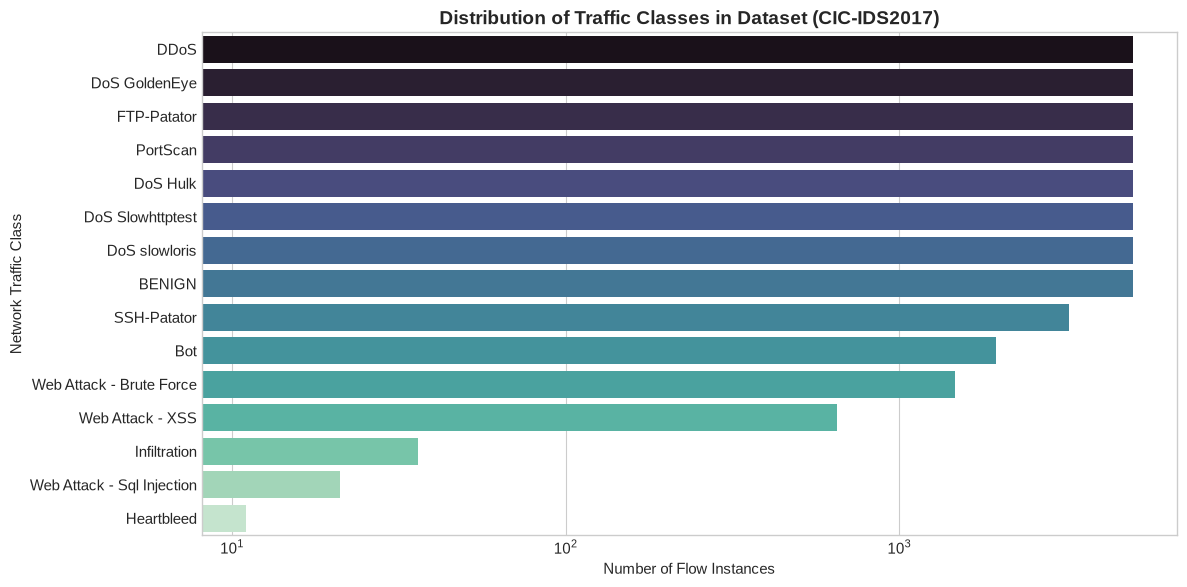

In [6]:
# Inspect Class Distribution
class_distribution = df['Label'].value_counts()
print("Class Distribution Across Target Labels:")
display(pd.DataFrame({'Count': class_distribution, 'Percentage (%)': (class_distribution / len(df) * 100).round(2)}))

# Visualize Target Class Distribution
plt.figure(figsize=(12, 6))
sns.barplot(x=class_distribution.values, y=class_distribution.index, palette='mako')
plt.title("Distribution of Traffic Classes in Dataset (CIC-IDS2017)", fontsize=14, fontweight='bold')
plt.xlabel("Number of Flow Instances")
plt.ylabel("Network Traffic Class")
plt.xscale('log') # Logarithmic scale to clearly display both frequent and rare attack classes
plt.tight_layout()
plt.show()


## 4. Data Preprocessing & Leakage Prevention

### Preprocessing Strategy:
1. **Target Separation:** Separate feature matrix `X` from target series `y` (`Label`).
2. **Identification of Invariant Features:** Drop zero-variance/constant features that convey zero predictive signal.
3. **Infinite and Missing Value Imputation:** Replace any residual infinite numbers with numerical upper-bounds and impute clean values.
4. **Stratified Train-Test Splitting:** Allocate 80% to the training partition and 20% to the held-out test partition using stratified sampling on `y`, guaranteeing identical class representations across splits.
5. **Feature Scaling:** For distance- and gradient-based models like Logistic Regression, scale features via `StandardScaler`. Standard scaling is placed strictly within a Scikit-learn `Pipeline` to prevent data leakage from test folds into training parameters.


In [7]:
# Separate features and target
X = df.drop(columns=['Label'])
y = df['Label']

feature_names = list(X.columns)
unique_classes = sorted(y.unique().tolist())

print(f"Number of feature dimensions: {len(feature_names)}")
print(f"Number of target classes: {len(unique_classes)}")
print(f"Classes: {unique_classes}")


Number of feature dimensions: 78
Number of target classes: 15
Classes: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']


In [8]:
# Stratified Train-Test Partitioning (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training set: {X_train.shape[0]} samples, {X_train.shape[1]} features")
print(f"Testing set:  {X_test.shape[0]} samples, {X_test.shape[1]} features")


Training set: 37885 samples, 78 features
Testing set:  9472 samples, 78 features


## 5. Model Training

We instantiate three classification pipelines:
1. **Logistic Regression Pipeline:** Scaled with `StandardScaler`, configured with `class_weight='balanced'` and `max_iter=500`.
2. **Decision Tree Classifier:** Configured with `class_weight='balanced'` and `random_state=42`.
3. **Random Forest Classifier (Primary Model):** Configured with 100 estimators, `class_weight='balanced'`, parallelized across CPU cores (`n_jobs=-1`), and `random_state=42`.


In [9]:
pipelines = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(max_iter=500, random_state=42, class_weight='balanced'))
    ]),
    'Decision Tree': Pipeline([
        ('classifier', DecisionTreeClassifier(random_state=42, class_weight='balanced'))
    ]),
    'Random Forest': Pipeline([
        ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1))
    ])
}

training_times = {}
fitted_models = {}

for name, pipe in pipelines.items():
    print(f"Training {name}...")
    t0 = time.time()
    pipe.fit(X_train, y_train)
    elapsed = time.time() - t0
    training_times[name] = elapsed
    fitted_models[name] = pipe
    print(f"  ✓ {name} completed in {elapsed:.2f} seconds.")


Training Logistic Regression...


  ✓ Logistic Regression completed in 26.50 seconds.
Training Decision Tree...


  ✓ Decision Tree completed in 0.92 seconds.
Training Random Forest...


  ✓ Random Forest completed in 0.73 seconds.


## 6. Model Evaluation & Benchmark Comparison

We evaluate every model on the held-out test set using:
- **Overall Accuracy**
- **Macro-averaged Precision**
- **Macro-averaged Recall**
- **Macro-averaged F1-Score** (Primary Model Selection Metric)

> **Why Macro F1-Score?**  
> In network intrusion detection, critical cyberattacks (such as Heartbleed, SQL Injection, Infiltration) occur far less frequently than common DDoS or port scans. Macro-averaged F1 calculates the unweighted mean of F1 scores across all classes, evaluating the model's true capability to detect rare and stealthy attack types rather than being artificially inflated by dominant benign flows.


In [10]:
evaluation_results = {}

for name, pipe in fitted_models.items():
    y_pred = pipe.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
    
    evaluation_results[name] = {
        'Accuracy': acc,
        'Macro Precision': prec,
        'Macro Recall': rec,
        'Macro F1-Score': f1,
        'Training Time (s)': training_times[name],
        'y_pred': y_pred,
        'report': classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    }

comparison_df = pd.DataFrame({
    name: {
        'Accuracy': res['Accuracy'],
        'Macro Precision': res['Macro Precision'],
        'Macro Recall': res['Macro Recall'],
        'Macro F1-Score': res['Macro F1-Score'],
        'Training Time (s)': res['Training Time (s)']
    }
    for name, res in evaluation_results.items()
}).T

print("=== Algorithm Performance Comparison ===")
display(comparison_df.style.format({
    'Accuracy': '{:.4f}',
    'Macro Precision': '{:.4f}',
    'Macro Recall': '{:.4f}',
    'Macro F1-Score': '{:.4f}',
    'Training Time (s)': '{:.2f}'
}).highlight_max(subset=['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-Score'], color='#2ea043'))


=== Algorithm Performance Comparison ===


,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Training Time (s)
Logistic Regression,0.9387,0.8061,0.8975,0.7997,26.50
Decision Tree,0.9790,0.9187,0.9070,0.9120,0.92
Random Forest,0.9804,0.9297,0.9057,0.9162,0.73


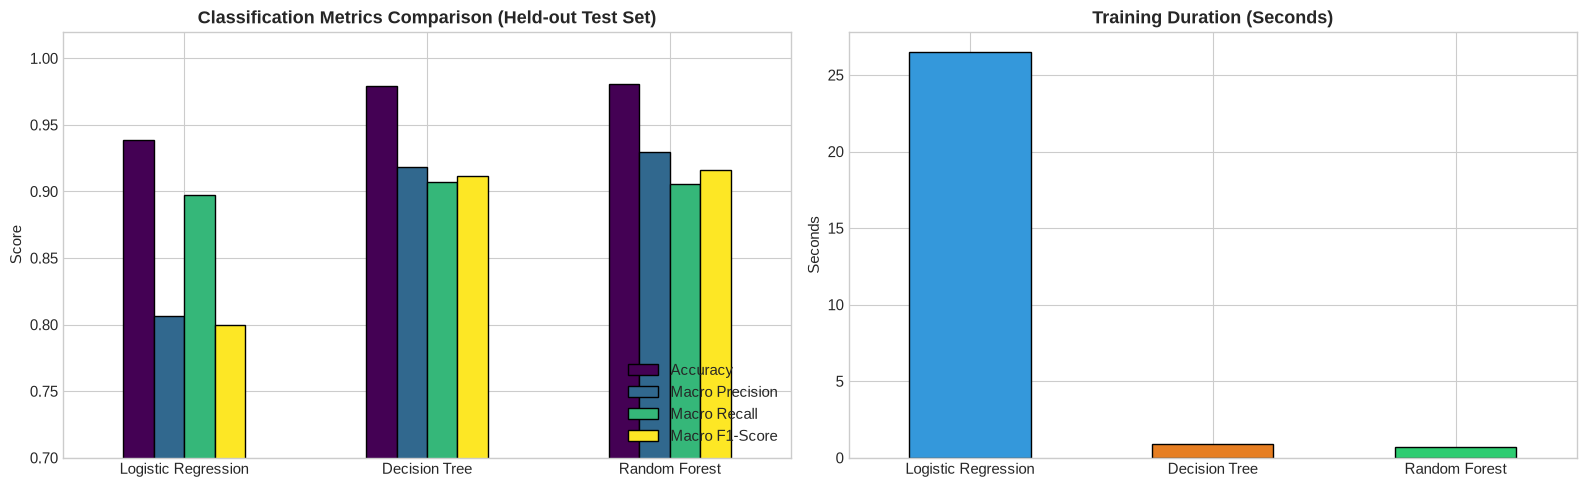

In [11]:
# Visualize Performance Comparison Metrics
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

comparison_df[['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-Score']].plot(
    kind='bar', ax=axes[0], colormap='viridis', edgecolor='black'
)
axes[0].set_title("Classification Metrics Comparison (Held-out Test Set)", fontweight='bold')
axes[0].set_ylabel("Score")
axes[0].set_ylim(0.7, 1.02)
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(loc='lower right')

comparison_df['Training Time (s)'].plot(
    kind='bar', ax=axes[1], color=['#3498db', '#e67e22', '#2ecc71'], edgecolor='black'
)
axes[1].set_title("Training Duration (Seconds)", fontweight='bold')
axes[1].set_ylabel("Seconds")
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


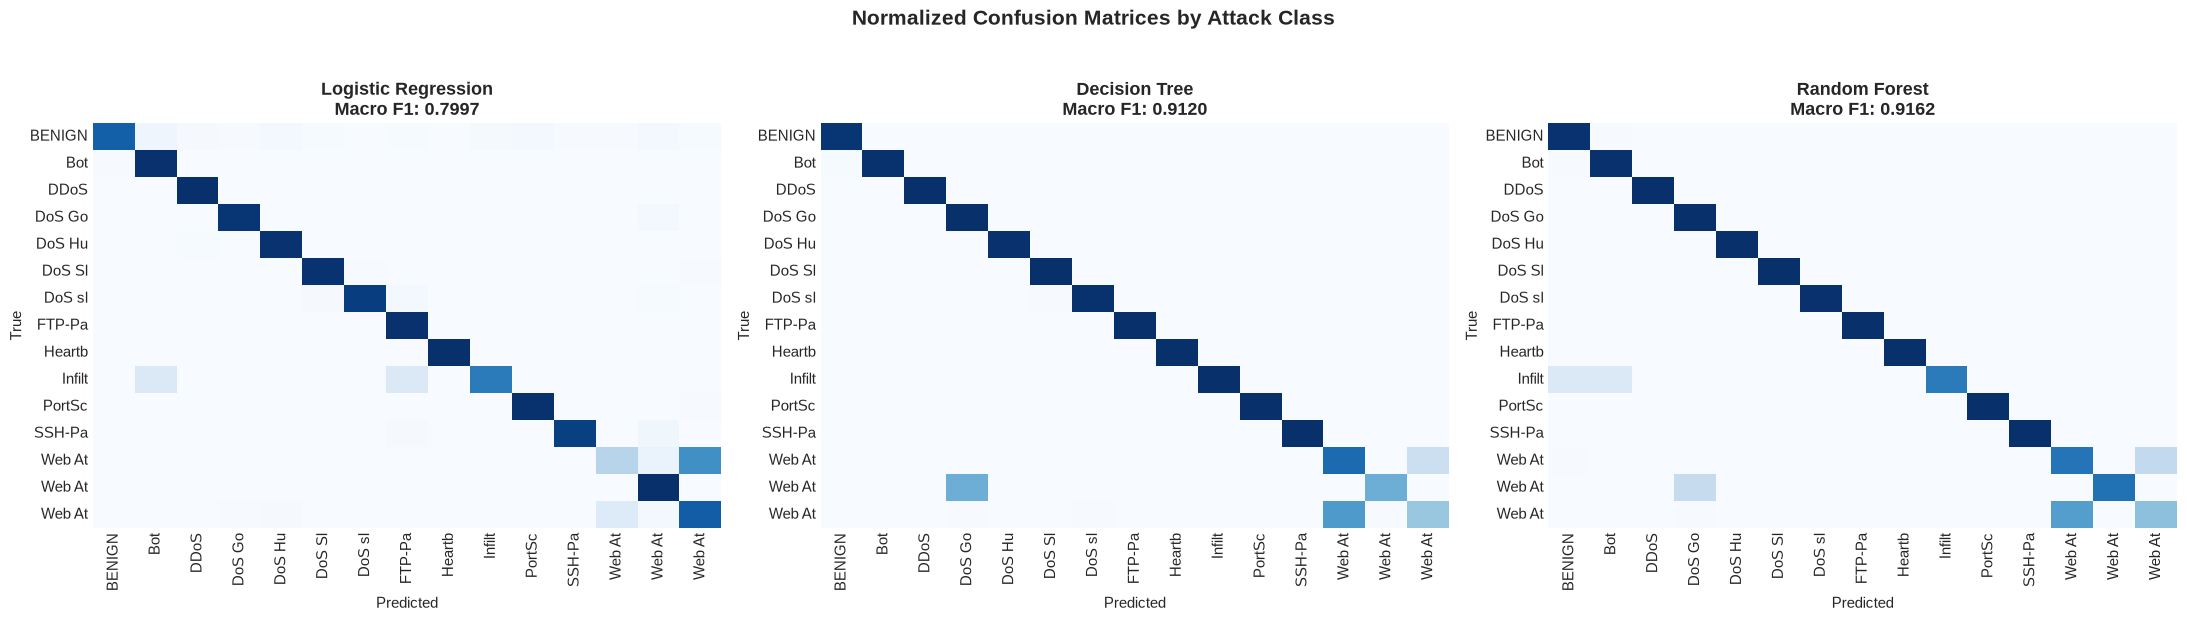

In [12]:
# Display Confusion Matrices for Top Models
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for ax, (name, res) in zip(axes, evaluation_results.items()):
    cm = confusion_matrix(y_test, res['y_pred'], labels=unique_classes)
    cm_norm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-10)
    
    sns.heatmap(cm_norm, ax=ax, cmap='Blues', cbar=False,
                xticklabels=[c[:6] for c in unique_classes],
                yticklabels=[c[:6] for c in unique_classes])
    ax.set_title(f"{name}\nMacro F1: {res['Macro F1-Score']:.4f}", fontweight='bold')
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.suptitle("Normalized Confusion Matrices by Attack Class", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 7. Best Model Selection & Model Export

We programmatically identify the best model based on the highest **Macro F1-Score** on the held-out test split, serialize the complete pipeline into `model.pkl`, along with inference metadata (feature ordering, target mapping, test metrics).


In [13]:
# Programmatic Best Model Selection
best_model_name = max(evaluation_results.keys(), key=lambda k: evaluation_results[k]['Macro F1-Score'])
best_pipeline = fitted_models[best_model_name]
best_metrics = evaluation_results[best_model_name]

print(f"Selected Best Model: {best_model_name}")
print(f"  Macro F1-Score: {best_metrics['Macro F1-Score']:.4f}")
print(f"  Overall Accuracy: {best_metrics['Accuracy']:.4f}")

# Package model and metadata for Streamlit inference
model_export_package = {
    'pipeline': best_pipeline,
    'model_name': best_model_name,
    'feature_names': feature_names,
    'classes': unique_classes,
    'metrics': {
        'accuracy': best_metrics['Accuracy'],
        'precision_macro': best_metrics['Macro Precision'],
        'recall_macro': best_metrics['Macro Recall'],
        'f1_macro': best_metrics['Macro F1-Score'],
        'report': best_metrics['report']
    },
    'all_models_summary': {
        k: {
            'accuracy': v['Accuracy'],
            'precision_macro': v['Macro Precision'],
            'recall_macro': v['Macro Recall'],
            'f1_macro': v['Macro F1-Score'],
            'train_time': v['Training Time (s)']
        } for k, v in evaluation_results.items()
    },
    'target_mapping': {c: ('BENIGN' if c == 'BENIGN' else 'ATTACK') for c in unique_classes},
    'metadata': {
        'dataset': 'CIC-IDS2017',
        'train_samples': len(X_train),
        'test_samples': len(X_test),
        'total_features': len(feature_names),
        'evaluation_metric': 'macro F1-score'
    }
}

MODEL_PATH = "model.pkl"
with open(MODEL_PATH, "wb") as f:
    pickle.dump(model_export_package, f)

print(f"✓ Model successfully serialized and exported to '{MODEL_PATH}' ({os.path.getsize(MODEL_PATH)/(1024*1024):.2f} MB)")


Selected Best Model: Random Forest
  Macro F1-Score: 0.9162
  Overall Accuracy: 0.9804
✓ Model successfully serialized and exported to 'model.pkl' (31.73 MB)


## 8. Verification and Inference Test

Load the exported `model.pkl` in an isolated check to verify that all inference capabilities, feature contracts, and predictions run without depending on global notebook state.


In [14]:
# Independent Verification
with open("model.pkl", "rb") as f:
    test_loaded_pkg = pickle.load(f)

test_pipe = test_loaded_pkg['pipeline']
sample_test_features = X_test.head(5)
sample_preds = test_pipe.predict(sample_test_features)
sample_probs = test_pipe.predict_proba(sample_test_features)

print("Inference Verification Successful:")
for i, (pred, actual) in enumerate(zip(sample_preds, y_test.head(5))):
    confidence = np.max(sample_probs[i]) * 100.0
    print(f"  Sample {i+1}: Predicted = {pred:<20} | Actual = {actual:<20} | Confidence = {confidence:.1f}%")


Inference Verification Successful:
  Sample 1: Predicted = DoS Slowhttptest     | Actual = DoS Slowhttptest     | Confidence = 100.0%
  Sample 2: Predicted = FTP-Patator          | Actual = FTP-Patator          | Confidence = 100.0%
  Sample 3: Predicted = BENIGN               | Actual = BENIGN               | Confidence = 82.0%
  Sample 4: Predicted = PortScan             | Actual = PortScan             | Confidence = 100.0%
  Sample 5: Predicted = DoS slowloris        | Actual = DoS slowloris        | Confidence = 100.0%


## 9. Google Colab Instructions & File Download

If running this notebook in **Google Colab**, download the generated `dataset.csv` and `model.pkl` files to place them in your project directory alongside `app.py`:

```python
from google.colab import files

# Download the trained model
files.download('model.pkl')

# Download the training dataset
files.download('dataset.csv')
```

### Running the Streamlit Dashboard:
In your terminal, navigate to the folder containing `app.py`, `model.pkl`, and `dataset.csv`, then run:
```bash
streamlit run app.py
```

